In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import json, pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras
from keras.utils import set_random_seed
from keras.models import Model
from keras.optimizers import Adam
from keras.layers import Conv1D, Conv2D, Dense, Bidirectional, LSTM, GRU, Activation, BatchNormalization, Dropout,\
      AveragePooling1D, AveragePooling2D, Flatten, Reshape, Input, add, concatenate

In [3]:
PICKLE_PATH = "/content/drive/MyDrive/AUT/Project/Features/DATA_MFCC30_MEL128.pkl"

In [4]:
def load_data():
    with open(PICKLE_PATH, "rb") as input:
        DATA = pickle.load(input)

    X1 = np.array(DATA["mfccs"], dtype=np.float32)
    X2 = np.array(DATA["mel_spec"], dtype=np.float32)
    y1 = np.array(DATA["labels"]["instrument"], dtype=np.int8)
    y2 = np.array(DATA["labels"]["scale"], dtype=np.int8)

    return X1, X2, y1, y2

In [5]:
def tmp_load_data(num_data=900):

    X1 = np.random.randn(num_data, 216, 90).astype(np.float32)
    X2 = np.random.randn(num_data, 216, 128).astype(np.float32)
    y1 = np.random.randint(5, size=num_data, dtype=np.int8)
    y2 = np.random.randint(7, size=num_data, dtype=np.int8)

    X1_train, X1_test, X2_train, X2_test, y1_train, y1_test, y2_train, y2_test = \
        train_test_split(X1, X2, y1, y2, test_size=0.15, shuffle=True, random_state=0)
    
    X1_test, X1_val, X2_test, X2_val, y1_test, y1_val, y2_test, y2_val = \
        train_test_split(X1_test, X2_test, y1_test, y2_test, test_size=0.5, shuffle=True, random_state=0)
    
    # X2: 4d array -> (num_samples, 216, 128, 1)
    X_train = (X1_train, X2_train[..., np.newaxis])
    X_test = (X1_test, X2_test[..., np.newaxis])
    X_val = (X1_val, X2_val[..., np.newaxis])
    
    Y_train = (y1_train, y2_train)
    Y_test = (y1_test, y2_test)
    Y_val = (y1_val, y2_val)
    
    # return X1_train, X1_test, X1_val, X2_train, X2_test, X2_val, y1_train, y1_test, y1_val, y2_train, y2_test, y2_val
    return X_train, X_test, X_val, Y_train, Y_test, Y_val

In [6]:
def prepare_dataset():
    X1, X2, y1, y2 = load_data()

    X1_train, X1_test, X2_train, X2_test, y1_train, y1_test, y2_train, y2_test = \
        train_test_split(X1, X2, y1, y2, test_size=0.15, shuffle=True, random_state=0)
    
    X1_test, X1_val, X2_test, X2_val, y1_test, y1_val, y2_test, y2_val = \
        train_test_split(X1_test, X2_test, y1_test, y2_test, test_size=0.5, shuffle=True, random_state=0)
    
    # X2: 4d array -> (num_samples, 216, 128, 1)
    X_train = (X1_train, X2_train[..., np.newaxis])
    X_test = (X1_test, X2_test[..., np.newaxis])
    X_val = (X1_val, X2_val[..., np.newaxis])
    
    Y_train = (y1_train, y2_train)
    Y_test = (y1_test, y2_test)
    Y_val = (y1_val, y2_val)
    
    return X_train, X_test, X_val, Y_train, Y_test, Y_val

In [7]:
def Residual_Conv1D(model, num_filters):

    def conv1D(model, dropout):
        model = Conv1D(filters=num_filters, kernel_size=5, padding='same')(model)
        model = Dropout(dropout)(model)
        model = BatchNormalization()(model)
        model = Activation('relu')(model)
        return model

    model_in = model

    model = conv1D(model, dropout=0.1)
    model = conv1D(model, dropout=0.2)

    shortcut = Conv1D(filters=num_filters, kernel_size=3, padding='same')(model_in)
    shortcut = BatchNormalization()(shortcut)

    model_out = add([shortcut, model])
    model_out = Activation('relu')(model_out)

    return model_out


In [8]:
def Residual_Conv2D(model, num_filters, in_shape):

    def conv2D(model, dropout):
        model = Conv2D(filters=num_filters, kernel_size=3, padding='same')(model)
        model = Dropout(dropout)(model)
        model = BatchNormalization()(model)
        model = Activation('relu')(model)
        return model

    model_in = model

    model = conv2D(model, dropout=0.1)
    model = conv2D(model, dropout=0.2)

    shortcut = Conv2D(filters=num_filters, kernel_size=1, padding='same')(model_in)
    shortcut = BatchNormalization()(shortcut)

    model_out = add([shortcut, model])
    model_out = Activation('relu')(model_out)
    model_out = Reshape((in_shape[0], in_shape[1]*num_filters))(model_out)

    return model_out

In [9]:
def BiGRU(model, num_units, return_seq=True):
    model = Bidirectional(GRU(units=num_units, return_sequences=return_seq))(model)
    model = BatchNormalization()(model)
    return model

In [10]:
def Encoder(model):
    
    model = BiGRU(model, num_units=256)
    model = BiGRU(model, num_units=128)
    model = BiGRU(model, num_units=64)

    return model

In [11]:
def Decoder(model):

    model = BiGRU(model, num_units=32)
    model = BiGRU(model, num_units=64)
    model = BiGRU(model, num_units=128)
    model = BiGRU(model, num_units=256, return_seq=False)

    return model

In [12]:
def FC_Dense(model, unit, alpha):
    model = Dense(units=unit, activation='relu', kernel_regularizer=keras.regularizers.l2(alpha))(model)
    model = Dropout(0.5)(model)

    return model

In [13]:
def Output(models):
    y1_output = Dense(units=5, activation='softmax', name='instrument')(models[0])
    y2_output = Dense(units=7, activation='softmax', name='scale')(models[1])

    return (y1_output, y2_output)

In [14]:
def build_model(input_shape_1D, input_shape_2D) -> Model:

    input_MFCC = Input(input_shape_1D)
    input_MEL = Input(input_shape_2D)

    model_in_1 = Residual_Conv1D(input_MFCC, num_filters=1024)
    model_in_2 = Residual_Conv2D(input_MEL, num_filters=8, in_shape=input_shape_2D)

    model = concatenate([model_in_1, model_in_2])

    model = Encoder(model)
    model = Decoder(model)

    model_out_1 = FC_Dense(model, unit=16, alpha=0.05)
    model_out_2 = FC_Dense(model, unit=24, alpha=0.05)

    input = (input_MFCC, input_MEL)
    output = Output((model_out_1, model_out_2))
    model = Model(inputs=input, outputs=output)

    return model

In [15]:
X_train, X_test, X_val, Y_train, Y_test, Y_val = prepare_dataset()
set_random_seed(0)
model = build_model(
    input_shape_1D=(X_train[0].shape[1], X_train[0].shape[2]),
    input_shape_2D=(X_train[1].shape[1], X_train[1].shape[2], X_train[1].shape[3])
)
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 216, 128, 1  0           []                               
                                )]                                                                
                                                                                                  
 input_1 (InputLayer)           [(None, 216, 90)]    0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 216, 128, 8)  80          ['input_2[0][0]']                
                                                                                                  
 conv1d (Conv1D)                (None, 216, 1024)    461824      ['input_1[0][0]']            

In [16]:
optimizer = Adam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss={
        'instrument': 'sparse_categorical_crossentropy',
        'scale': 'sparse_categorical_crossentropy'
    },
    metrics={
        'instrument': ['accuracy'],
        'scale': ['accuracy']
    }
)

history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=256,
                    epochs=130)

Epoch 1/130
30/30 [==============================] - 90s 2s/step - loss: 6.0756 - instrument_loss: 0.7290 - scale_loss: 2.0872 - instrument_accuracy: 0.7384 - scale_accuracy: 0.2115 - val_loss: 5.7691 - val_instrument_loss: 1.1831 - val_scale_loss: 1.9386 - val_instrument_accuracy: 0.6080 - val_scale_accuracy: 0.1612
Epoch 2/130
30/30 [==============================] - 42s 1s/step - loss: 4.1288 - instrument_loss: 0.3373 - scale_loss: 1.6224 - instrument_accuracy: 0.8939 - scale_accuracy: 0.3600 - val_loss: 4.4355 - val_instrument_loss: 0.8594 - val_scale_loss: 1.8641 - val_instrument_accuracy: 0.7382 - val_scale_accuracy: 0.3240
Epoch 3/130
30/30 [==============================] - 43s 1s/step - loss: 2.9494 - instrument_loss: 0.2690 - scale_loss: 1.2881 - instrument_accuracy: 0.9237 - scale_accuracy: 0.5092 - val_loss: 3.1869 - val_instrument_loss: 0.4566 - val_scale_loss: 1.6353 - val_instrument_accuracy: 0.8861 - val_scale_accuracy: 0.4334
Epoch 4/130
30/30 [========================

In [17]:
loss, instrument_loss, scale_loss, instrument_accuracy, scale_accuracy = model.evaluate(X_test, Y_test)
print(f"\nTest Results:\n")
print(f"Total Loss: {loss}")
print(f"Instrument Loss: {instrument_loss}")
print(f"Scale Loss: {scale_loss}")
print(f"Instrument Accuracy on Test Set: {instrument_accuracy}")
print(f"Scale Accuracy on Test Set: {scale_accuracy}")

22/22 [==============================] - 3s 96ms/step - loss: 0.2098 - instrument_loss: 0.0422 - scale_loss: 0.1222 - instrument_accuracy: 0.9911 - scale_accuracy: 0.9748

Test Results:

Total Loss: 0.20984923839569092
Instrument Loss: 0.042162299156188965
Scale Loss: 0.12221251428127289
Instrument Accuracy on Test Set: 0.9911110997200012
Scale Accuracy on Test Set: 0.9748148322105408


In [18]:
def plot_history(history):

    def plot_result(metrics, labels, y_label, title, location):
        plt.plot(history.history[metrics[0]], label=labels[0])
        plt.plot(history.history[metrics[1]], label=labels[1])
        plt.title(title)
        plt.xlabel("Epoch")
        plt.ylabel(y_label)
        plt.legend(loc=location)
        # plt.savefig("/content/drive/MyDrive/proj/pic/MFCC_B128_E130_M30/" + title + ".png")
        plt.show()
        print("\n\n")

    # create accuracy sublpot
    plot_result(metrics=("instrument_accuracy", "val_instrument_accuracy"),
                 labels=("Instrument Train Accuracy", "Instrument Test Accuracy"),
                 y_label="Accuracy", title="Instrument Accuracy Evaluation", location="lower right")

    plot_result(metrics=("instrument_loss", "val_instrument_loss"),
                 labels=("Instrument Train Error", "Instrument Test Error"),
                 y_label="Loss", title="Instrument Error Evaluation", location="upper right")
    
    plot_result(metrics=("scale_accuracy", "val_scale_accuracy"),
                 labels=("Scale Train Accuracy", "Scale Test Accuracy"),
                 y_label="Accuracy", title="Scale Accuracy Evaluation", location="lower right")
    
    plot_result(metrics=("scale_loss", "val_scale_loss"),
                 labels=("Scale Train Error", "Scale Test Error"),
                 y_label="Loss", title="Scale Error Evaluation", location="upper right")

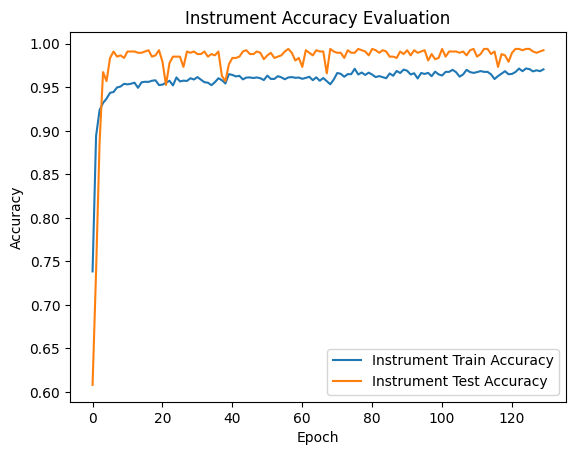

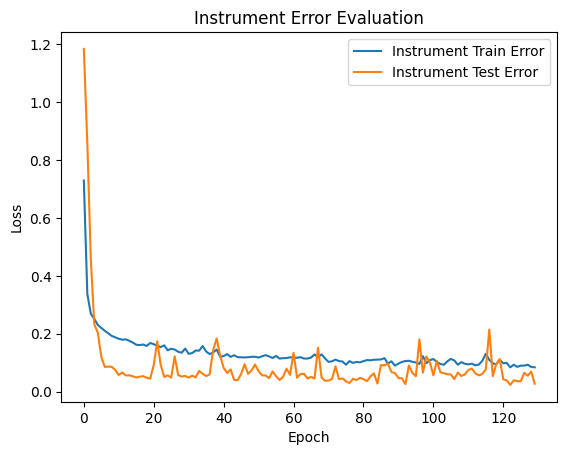

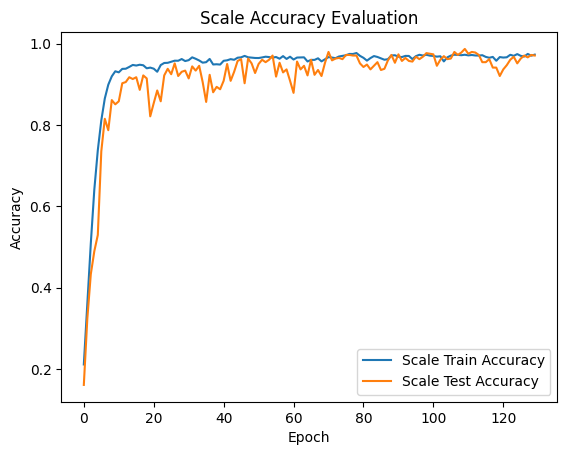

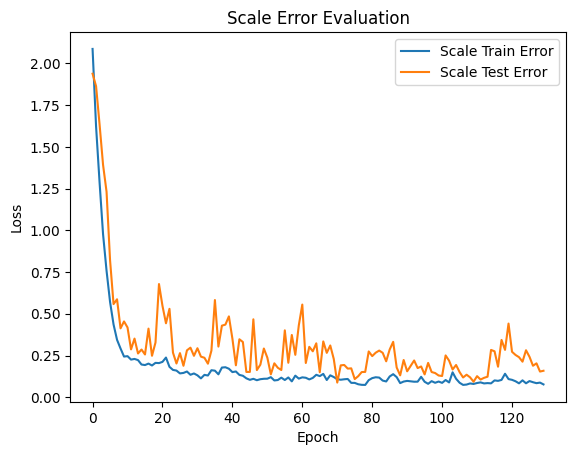

In [19]:
plot_history(history)

In [20]:
model.save(filepath="/content/drive/MyDrive/AUT/Project/Models/Conv1D-MFCCs_Conv2D-MEL_EN-GRU_DE-GRU")